In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('placement2.csv')

In [3]:
df.head()


,cgpa,package
0,6.89,3.26
1,5.12,1.98
2,7.82,3.25
3,7.42,3.67
4,6.94,3.57


Text(0, 0.5, 'Package(in lpa)')

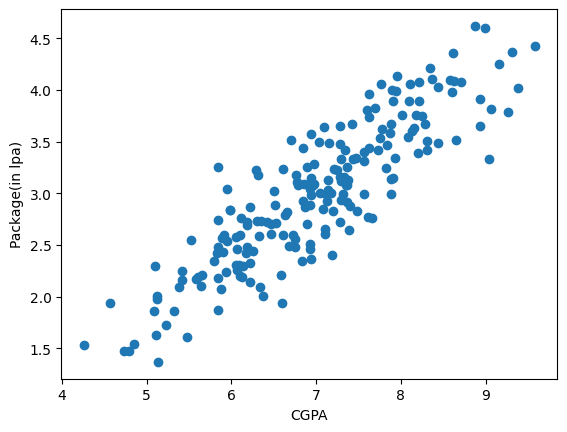

In [4]:
plt.scatter(df['cgpa'],df['package'])
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [5]:
X = df.iloc[:,0:1]
y = df.iloc[:,-1]

In [6]:
y

0      3.26
1      1.98
2      3.25
3      3.67
4      3.57
       ... 
195    2.46
196    2.57
197    3.24
198    3.96
199    2.33
Name: package, Length: 200, dtype: float64

In [7]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [8]:
from sklearn.linear_model import LinearRegression


In [9]:
lr = LinearRegression()

In [10]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


Text(0, 0.5, 'Package(in lpa)')

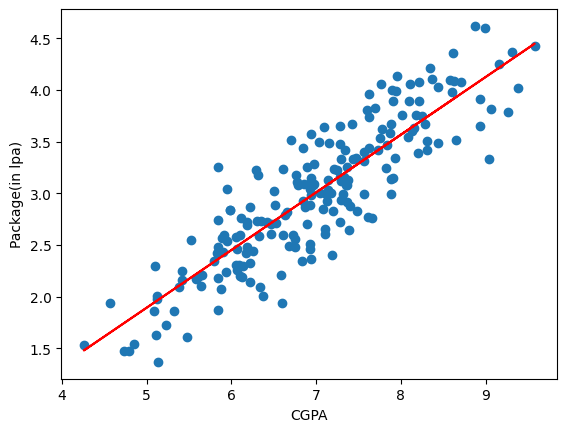

In [11]:
plt.scatter(df['cgpa'],df['package'])
plt.plot(X_train,lr.predict(X_train),color='red')
plt.xlabel('CGPA')
plt.ylabel('Package(in lpa)')

In [12]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [13]:
y_pred = lr.predict(X_test)

In [15]:
y_pred

array([3.89111601, 3.09324469, 2.38464568, 2.57434935, 1.6537286 ,
       1.77647803, 2.07219258, 2.93143862, 3.76278706, 2.93701814,
       4.09197872, 3.51170867, 2.97049525, 2.40138424, 3.18809652,
       3.46707251, 1.94386362, 3.24389172, 2.97607477, 3.41685683,
       2.55761079, 3.16577844, 2.85890486, 3.12114229, 3.68467378,
       2.8700639 , 3.49497011, 3.34432308, 3.91901361, 1.96060218,
       3.65119666, 3.2104146 , 3.74046898, 2.7863711 , 2.78079158,
       3.27178932, 3.52844723, 2.61340599, 2.65804215, 2.71383735])

In [16]:
y_test.values

array([4.1 , 3.49, 2.08, 2.33, 1.94, 1.48, 1.86, 3.09, 4.21, 2.87, 3.65,
       4.  , 2.89, 2.6 , 2.99, 3.25, 1.86, 3.67, 2.37, 3.42, 2.48, 3.65,
       2.6 , 2.83, 4.08, 2.56, 3.58, 3.81, 4.09, 2.01, 3.63, 2.92, 3.51,
       1.94, 2.21, 3.34, 3.34, 3.23, 2.01, 2.61])

In [18]:
print("MAE",mean_absolute_error(y_test,y_pred))

MAE 0.2884710931878175


In [19]:
print("MSE",mean_squared_error(y_test,y_pred))

MSE 0.12129235313495527


In [20]:
print("RMSE",np.sqrt(mean_squared_error(y_test,y_pred)))

RMSE 0.34827051717731616


In [23]:
print("R2 Score",r2_score(y_test,y_pred))

r2 = r2_score(y_test,y_pred)

R2 Score 0.780730147510384


In [27]:
# Adjusted R2 Score 
n = X_test.shape[0]
n

40

In [28]:
1 - ((1-r2)*(n-1)/(n-1-1))

0.7749598882343415

In [29]:
new_df1 = df.copy()
new_df1['random_feature'] = np.random.random(200)

new_df1 = new_df1[['cgpa','random_feature','package']]
new_df1.head()

,cgpa,random_feature,package
0,6.89,0.065986,3.26
1,5.12,0.878072,1.98
2,7.82,0.563284,3.25
3,7.42,0.745319,3.67
4,6.94,0.631557,3.57


Text(0, 0.5, 'Package(in lpa)')

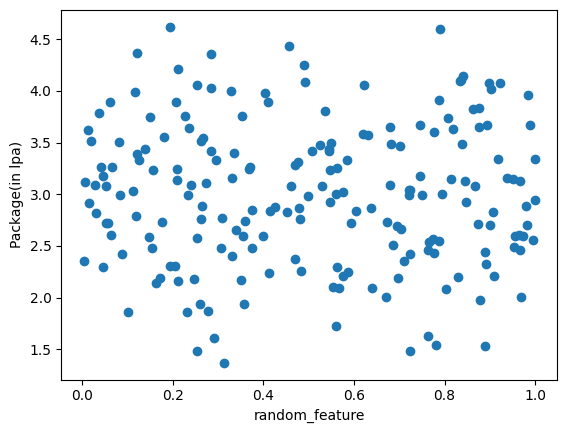

In [30]:
plt.scatter(new_df1['random_feature'],new_df1['package'])
plt.xlabel('random_feature')
plt.ylabel('Package(in lpa)')


In [31]:
X = new_df1.iloc[:,0:2]
y = new_df1.iloc[:,-1]


In [32]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [33]:
lr = LinearRegression()

In [34]:
lr.fit(X_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [35]:
y_pred = lr.predict(X_test)

In [38]:
print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.7806837258245648


In [39]:
1 - ((1-r2)*(n-1)/(n-1-1))

0.7749122449252113

In [40]:
new_df2 = df.copy()

new_df2['iq'] = new_df2['package'] + (np.random.randint(-12,12,200)/10)

new_df2 = new_df2[['cgpa','iq','package']]

In [41]:
new_df2.sample(5)

,cgpa,iq,package
189,8.11,4.96,4.06
71,7.47,4.34,3.34
177,7.09,2.44,3.64
91,6.22,3.14,2.14
185,6.31,3.38,3.18


Text(0, 0.5, 'Package(in lpa)')

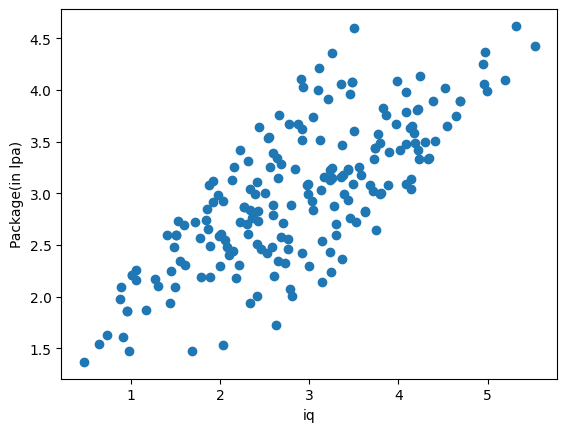

In [42]:
plt.scatter(new_df2['iq'],new_df2['package'])
plt.xlabel('iq')
plt.ylabel('Package(in lpa)')

In [44]:
np.random.randint(-12,12,200)

array([  0,  -3,  11,   5,  -3,  -3,   5,   6,  11,   5,   7,   3, -12,
        -3,   4,  -3,   4,  -4,  -4, -12,  10,   4, -10, -11,   8,  -9,
         5,  -2, -11,   0,  10,   1,   1,  -3,  -4,  -8,  -6,   0,   4,
        -3,   4,  -4,   8,   1,  -3, -11,   8,  -7,   4,   8, -12,  -1,
         1,  -4,   6,   7,  11, -11,  -2,   3,  -3,   0,  -6,   0,   4,
        -9,  -4,   1,   1,   0,   6,  10,   3,   4,   4,  -8,   4,  -9,
        -4,  -6,  -9, -10,   1,   1,   8,  -1,  -1,   5, -12,  -7,  -3,
         7,  -5,  -9,  -7,  11,   5,  10,  11,   4,  -6,   6,   0,  -4,
         2,  -2,  -6,  11,  -7,   0,  -4,   8,  -8,  -5,  -4,  10,  -9,
         8,   7,  -7,  -4,  -4,   6,  -3,   6,   2,  10,  -6,  10,   7,
        -5,   5,   3,  -1,  -6,  -2,  10,   6,  -4,  10,   9,  11,   3,
         8,   2,   6,   1,  10,   1,  -4,  -8,  -4, -12,   4,   8, -10,
         0,  -6, -10,   2,  -3,   3,  -2,   9,  -5,  11,   7,  -6,  -8,
        -1,  -5,   6,   3,  -3,  10,  -6,   4,   4,  -5,   3,   

In [45]:
X = new_df2.iloc[:,0:2]
y = new_df2.iloc[:,-1]

In [46]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [47]:
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)

In [48]:
print("R2 score",r2_score(y_test,y_pred))
r2 = r2_score(y_test,y_pred)

R2 score 0.8016489235424494


In [49]:
1 - ((1-r2)*(n-1)/(n-1-1))

0.7964291583725138